# Global Cities: Exploring Population Patterns Across Regions
**Name:** Ashley  Raber  
**Date:** November 15, 2026  
**Disclaimer** I was sick for many of the classes and was behind--I did use ai to help me out and explain things to me as I was going along.


## Part 1: Dataset Selection and Introduction

### Dataset Overview
* **Dataset:** World's Largest Cities JSON Dataset  
* **Source:** [JSONLint Free JSON Datasets](https://jsonlint.com/datasets)  
* **Why I Chose It:** I wanted to see where the biggest cities in the world are located and whether geography plays a role in how big a city gets  
* **What Each Row Represents:** Each row is one of the 30 most populated cities on Earth, showing its name, country, population, latitude/longitude coordinates, and timezone.  

### Variables I Am Investigating
* **Quantitative Variables:**
  * `population`: Total population of the city in millions.
  * `lat` and `lon`: Latitude and longitude coordinates.
  * `abs_lat`: Absolute latitude, which tells us how many degrees away from the equator a city is.
* **Categorical (Group) Variables:**
  * `region`: The continent/region pulled from the timezone .
  * `region_group`: Splits the cities into two main groups asia and non-asia.

### Research Question & Hypothesis
* **Research Question:** Are the biggest cities in Asia noticeably larger than major cities in other parts of the world, and does how close a city is to the equator affect its population?
* **Hypothesis:** I think cities in Asia will have larger populations on average than cities in other regions, and cities closer to warm, latitude areas will be larger than cities far north.

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

with open('world-cities.json', 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

df = pd.DataFrame(raw_data['cities'])

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.info()

df.head()

Dataset shape: 30 rows, 6 columns

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        30 non-null     str    
 1   country     30 non-null     str    
 2   population  30 non-null     int64  
 3   lat         30 non-null     float64
 4   lon         30 non-null     float64
 5   timezone    30 non-null     str    
dtypes: float64(2), int64(1), str(3)
memory usage: 2.4 KB


,name,country,population,lat,lon,timezone
0,Tokyo,Japan,37400068,35.6762,139.6503,Asia/Tokyo
1,Delhi,India,28514000,28.7041,77.1025,Asia/Kolkata
2,Shanghai,China,25582000,31.2304,121.4737,Asia/Shanghai
3,São Paulo,Brazil,21650000,-23.5505,-46.6333,America/Sao_Paulo
4,Mexico City,Mexico,21581000,19.4326,-99.1332,America/Mexico_City


### How I Cleaned and Prepared the Data
1. **No Missing Data:** All 30 cities have complete information with no blank values or duplicates.
2. **Made Population Easier to Read (`pop_millions`):** Numbers like `37,400,068` would be harder toread ona graph, so I divided `population` by 1,000,000 to show it in millions.
3. **Measured Distance from the Equator (`abs_lat`):** Cities south of the equator have negative latitude numbers. Taking the absolute value (`abs()`) removes the negative sign so we can compare distance from the equator for all cities fairly.
4. **Created Region Groups (`region` and `region_group`):** The original data didn't have a continent column, so I split the `timezone` text at the `/` mark  which means i had anything that was in asia as asia with no extra words. Then I made a second column to compare `Asia` against `Non-Asia` cities.

In [3]:
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate city names:", df['name'].duplicated().sum())

# measuring how many degrees away from the equator each city is and measuring how far away the city is awy from the equator
df['pop_millions'] = df['population'] / 1_000_000
df['abs_lat'] = df['lat'].abs()
df['region'] = df['timezone'].str.split('/').str[0]
# label cities as "Asia" if their region is Asia, otherwise "Non-Asia"
df['region_group'] = np.where(df['region'] == 'Asia', 'Asia', 'Non-Asia')

print("\nCities per Region:")
print(df['region'].value_counts())

df[['name', 'country', 'region', 'region_group', 'pop_millions', 'abs_lat']].head(10)

Missing values per column:
 name          0
country       0
population    0
lat           0
lon           0
timezone      0
dtype: int64

Duplicate city names: 0

Cities per Region:
region
Asia       17
America     6
Europe      4
Africa      3
Name: count, dtype: int64


,name,country,region,region_group,pop_millions,abs_lat
0,Tokyo,Japan,Asia,Asia,37.400068,35.6762
1,Delhi,India,Asia,Asia,28.514000,28.7041
2,Shanghai,China,Asia,Asia,25.582000,31.2304
3,São Paulo,Brazil,America,Non-Asia,21.650000,23.5505
4,Mexico City,Mexico,America,Non-Asia,21.581000,19.4326
5,Cairo,Egypt,Africa,Non-Asia,20.076000,30.0444
6,Mumbai,India,Asia,Asia,19.980000,19.0760
7,Beijing,China,Asia,Asia,19.618000,39.9042
8,Dhaka,Bangladesh,Asia,Asia,19.578000,23.8103
9,Osaka,Japan,Asia,Asia,19.281000,34.6937


---

## Part 2: Exploring the Data with Visualizations

### 1. Histogram: How City Populations Are Spread Out
the histogram groups numbers into ranges and uses bars to show how many cities fall into each range. This helps me see what a "normal" city size looks like and if any cities are bigger than the others.

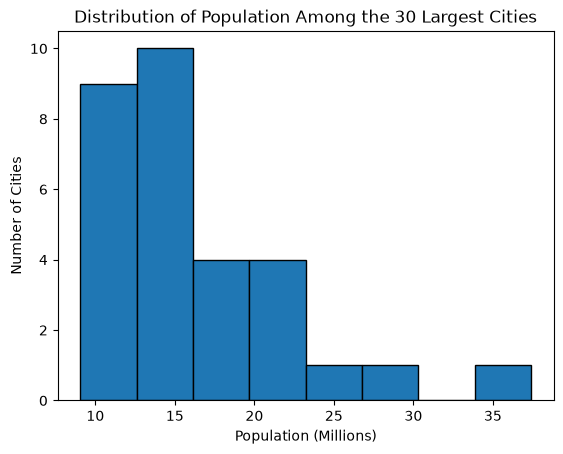

In [4]:
plt.hist(df['pop_millions'], bins=8, edgecolor='black')
plt.title('Distribution of Population Among the 30 Largest Cities')
plt.xlabel('Population (Millions)')
plt.ylabel('Number of Cities')
plt.show()

**What the Histogram Shows:**
* **Shape of the Distribution:** The graph is skewed to the right, meaning most of the bars are bunched up on the left side. Almost all of the top 30 cities have between 10 million and 22 million people, with the biggest group between 10 and 15 million.
* **Unusual Values:** There is a long tail stretching to the right because of Tokyo, which is way larger than every other city, followed by Delhi and Shanghai.
* **How Bin Choice Affects the Chart:** Picking `bins=8` splits the data into chunks of about 3.5 million people each. This works well because it shows the main crowd of cities clearly while still separating Tokyo on the far right. If I used too few bins, Tokyo would blend into the other big cities; if I used too many, there would be lots of empty gaps.

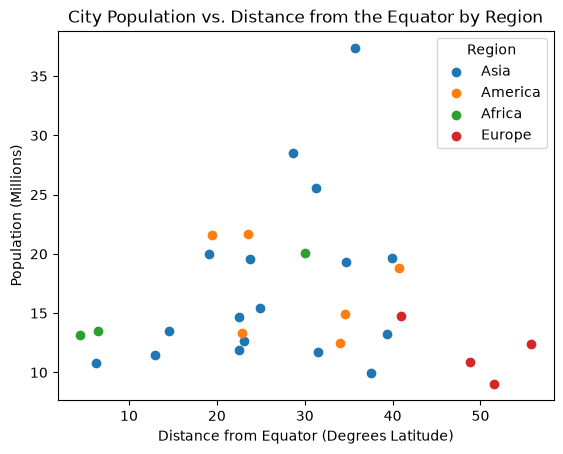

In [5]:
regions = df['region'].unique()

for region in regions:
    subset = df[df['region'] == region]
    plt.scatter(subset['abs_lat'], subset['pop_millions'], label=region)

plt.title('City Population vs. Distance from the Equator by Region')
plt.xlabel('Distance from Equator (Degrees Latitude)')
plt.ylabel('Population (Millions)')
plt.legend(title='Region')
plt.show()

### 2. Scatter Plot: Distance from the Equator vs. Population
A scatter plot uses dots to compare two number variables at once. Here, the x-axis shows how far a city is from the equator (`abs_lat`), and the y-axis shows its population (`pop_millions`). Coloring the dots by region lets us see where different continents sit on the map.

**What the Scatter Plot Shows:**
* **Overall Pattern:** There is no straight-line pattern between distance from the equator and population size—big cities exist near the equator, in the middle latitudes, and far north.
* **Group Patterns:** Even without a straight line, coloring by region shows that the biggest Asian cities all cluster in a middle band. European cities sit much further north  and have smaller populations.

### 3. Boxplot: Comparing Populations Across Regions
A boxplot compares different groups side by side. The line inside each box shows the median , the box shows the middle 50% of cities, and any dots outside the lines show outliers.

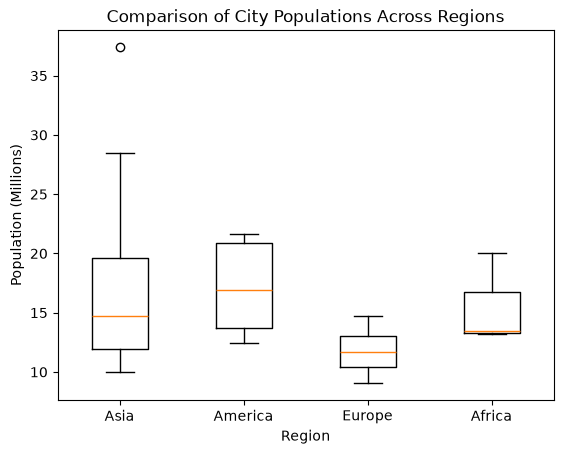

In [6]:
region_order = ['Asia', 'America', 'Europe', 'Africa']
grouped_data = [df[df['region'] == r]['pop_millions'] for r in region_order]

plt.boxplot(grouped_data, tick_labels=region_order)
plt.title('Comparison of City Populations Across Regions')
plt.xlabel('Region')
plt.ylabel('Population (Millions)')
plt.show()

**What the Boxplot Shows:**
* **Medians :** Asia has the highest median population at around, which is noticeably higher than America, Africa, and Europe.
* **Spread and Outliers:** Asia has the biggest spread of all—its cities range from 10.0M all the way up to 37.4M, which shows up as an outlier dot at the top. Europe and Africa have very short boxes, which means their largest cities are all roughly the same size.

## Part 3: Improving My Visualizations

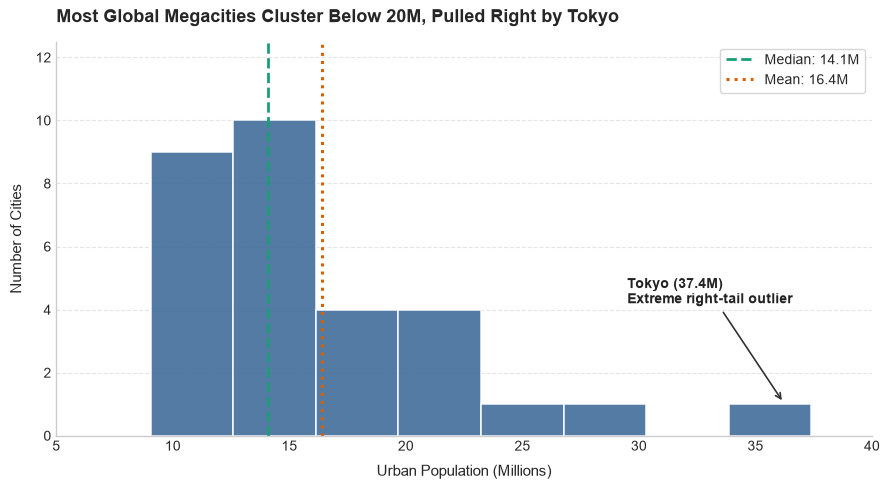

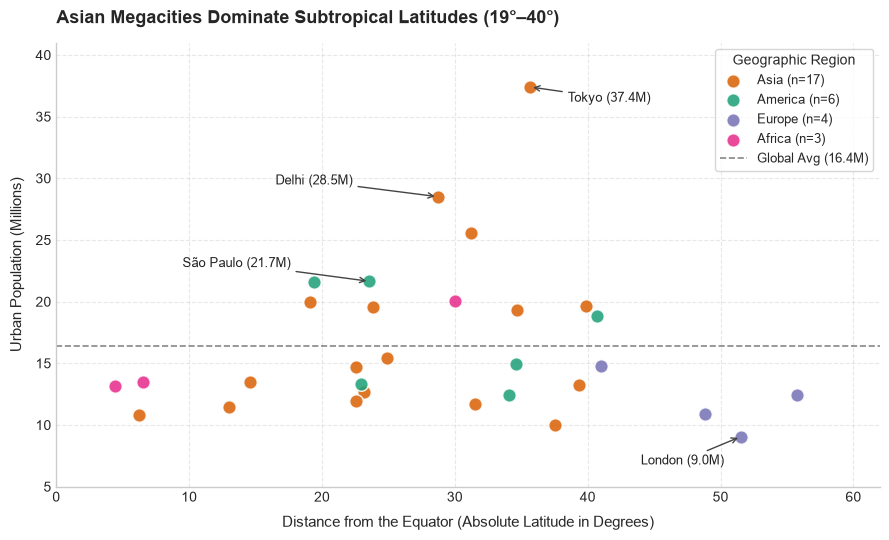

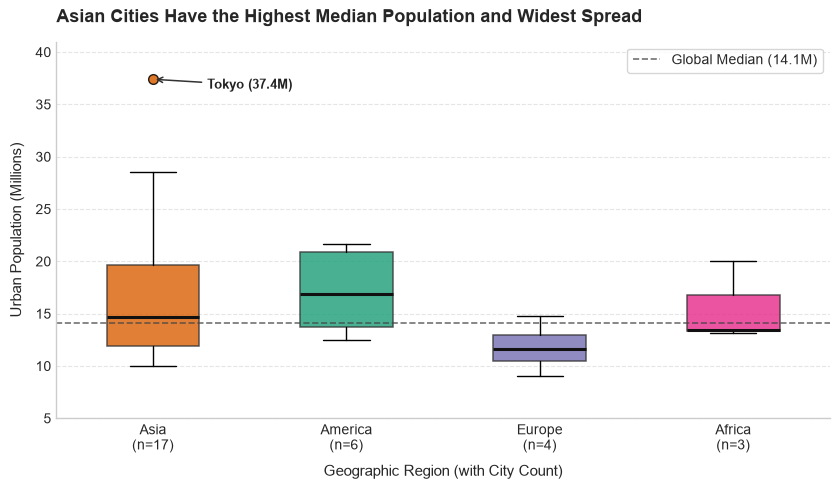

In [7]:
# this Applies a clean grid theme to all three  charts
plt.style.use('seaborn-v0_8-whitegrid')

region_colors = {
    'Asia': '#D95F02',      
    'America': '#1B9E77',   
    'Europe': '#7570B3',    
    'Africa': '#E7298A'     
}


fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(df['pop_millions'], bins=8, color='#3B6998', edgecolor='white', linewidth=1.2, alpha=0.88)

mean_pop = df['pop_millions'].mean()
median_pop = df['pop_millions'].median()

ax.axvline(median_pop, color='#1B9E77', linestyle='--', linewidth=2, label=f'Median: {median_pop:.1f}M')
ax.axvline(mean_pop, color='#D95F02', linestyle=':', linewidth=2.2, label=f'Mean: {mean_pop:.1f}M')

ax.annotate(
    'Tokyo (37.4M)\nExtreme right-tail outlier',
    xy=(36.2, 1.05), xytext=(29.5, 4.2),
    arrowprops=dict(arrowstyle='->', color='#333333', lw=1.2),
    fontsize=10, fontweight='bold', color='#222222'
)

ax.set_title('Most Global Megacities Cluster Below 20M, Pulled Right by Tokyo', fontsize=13, fontweight='bold', pad=14, loc='left')
ax.set_xlabel('Urban Population (Millions)', fontsize=11, labelpad=8)
ax.set_ylabel('Number of Cities', fontsize=11, labelpad=8)
ax.set_xlim(5, 40)
ax.set_ylim(0, 12.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', visible=False)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(frameon=True, facecolor='white', fontsize=10)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))

for region in ['Asia', 'America', 'Europe', 'Africa']:
    subset = df[df['region'] == region]
    ax.scatter(
        subset['abs_lat'], subset['pop_millions'],
        label=f"{region} (n={len(subset)})",
        color=region_colors[region],
        s=95, alpha=0.85, edgecolors='white', linewidth=1.1
    )

ax.axhline(mean_pop, color='#555555', linestyle='--', linewidth=1.2, alpha=0.7, label=f'Global Avg ({mean_pop:.1f}M)')

annotations = [
    ('Tokyo (37.4M)', (35.68, 37.40), (38.5, 36.2)),
    ('Delhi (28.5M)', (28.70, 28.51), (16.5, 29.5)),
    ('São Paulo (21.7M)', (23.55, 21.65), (9.5, 22.8)),
    ('London (9.0M)', (51.51, 9.05), (44.0, 6.8))
]
for text, xy, xytext in annotations:
    ax.annotate(
        text, xy=xy, xytext=xytext,
        arrowprops=dict(arrowstyle='->', color='#444444', lw=1),
        fontsize=9.5, fontweight='normal', color='#222222'
    )

ax.set_title('Asian Megacities Dominate Subtropical Latitudes (19°–40°)', fontsize=13, fontweight='bold', pad=14, loc='left')
ax.set_xlabel('Distance from the Equator (Absolute Latitude in Degrees)', fontsize=11, labelpad=8)
ax.set_ylabel('Urban Population (Millions)', fontsize=11, labelpad=8)
ax.set_xlim(0, 62)
ax.set_ylim(5, 41)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.45)
ax.legend(title='Geographic Region', frameon=True, facecolor='white', fontsize=9.5, title_fontsize=10)

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8.5, 5))

region_order = ['Asia', 'America', 'Europe', 'Africa']
grouped_data = [df[df['region'] == r]['pop_millions'] for r in region_order]

box = ax.boxplot(
    grouped_data,
    tick_labels=[f"{r}\n(n={len(df[df['region'] == r])})" for r in region_order],
    patch_artist=True,
    widths=0.48,
    medianprops=dict(color='#111111', linewidth=2.2),
    flierprops=dict(marker='o', markerfacecolor='#D95F02', markersize=7, alpha=0.85)
)

for patch, region in zip(box['boxes'], region_order):
    patch.set_facecolor(region_colors[region])
    patch.set_alpha(0.8)
    patch.set_edgecolor('#333333')
    patch.set_linewidth(1.1)

ax.axhline(median_pop, color='#444444', linestyle='--', linewidth=1.2, alpha=0.75, label=f'Global Median ({median_pop:.1f}M)')

ax.annotate(
    'Tokyo (37.4M)',
    xy=(1, 37.40), xytext=(1.28, 36.5),
    arrowprops=dict(arrowstyle='->', color='#333333', lw=1.1),
    fontsize=9.5, fontweight='bold', color='#222222'
)

ax.set_title('Asian Cities Have the Highest Median Population and Widest Spread', fontsize=13, fontweight='bold', pad=14, loc='left')
ax.set_xlabel('Geographic Region (with City Count)', fontsize=11, labelpad=8)
ax.set_ylabel('Urban Population (Millions)', fontsize=11, labelpad=8)
ax.set_ylim(5, 41)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.grid(axis='x', visible=False)
ax.legend(frameon=True, facecolor='white', fontsize=10)

plt.tight_layout()
plt.show()

### Why I Made These Design Changes

1. **Consistent Style & Highlight Colors :** I used the `seaborn-v0_8-whitegrid` style and picked one color for each region across all charts. I made Asia orange so it stands out immediately against the cool toned colors used for other regions.
2. **Clearer, Takeaway Titles:** Instead of boring titles like "Distribution of Population," I wrote titles that tell the reader what the chart proves 
3. **Reference Lines:** Adding dashed lines for the global mean and median gives the viewer an easy benchmark to see which cities and regions are above or below average.
4. **Direct Labels & Sample Sizes:** I addedarrows pointing directly to major cities so readers don't have to guess which dot is which. I also added `(n=...)` to show how many cities are in each region, since regions like Europe and Africa only have 3 cities each in this dataset.
5. **Removed Extra Clutter :** I removed the top and right black border lines around the charts, made the gridlines lighter, and used `tight_layout()` so nothing looks cramped.

## Part 4: Statistical Analysis

To test my hypothesis with math instead of just looking at graphs, I used `statsmodels` to run two checks:
1. **Group Comparison :** thsi was used to compare the average population of Asian cities compared to Non-Asian cities.
2. **Relationship Check:** this was used to  measure the correlation between distance from the equator and city population.

### What the Statistical Results Mean

1. **Comparing Asia vs. Non-Asia Cities:**
   * **Average Populations:** Non-Asian cities average 14.48 million people, while Asian cities average 18.38 million. That is 3.90 million more people per city on average.
   * **Is the Difference Statistically Significant? :** The p-value is 0.095. Because 0.095 is slightly higher than the  cutoff of 0.05, the difference is not significant enough to determaine anything.

2. **Distance from the Equator to Population:**
   * The correlation is r = 0.044 Since `r` is almost zero, there is no straight line relationship between the distance from the equator and the number of people.

3. **Assumptions and Limitations of the tests:**
   * **Outliers Affect Averages:** regression compares group averages, and Tokyo pulls Asia's average way up and creates a wide spread.
   * **Small Sample Size:** With only 30 cities total, it is hard for a statistical test to reach p < 0.05 unless the gap between groups is huge.
   * **Straight-Line Limit:** Correlation only checks for a straight line , so it misses any potential curved patterns

## Part 5: Conclusions and Reflection

### What I Learned and Was My Hypothesis Right?
From analyzing the world's 30 largest cities, I learned that most cities have between 10 million and 22 million people, with a median of 14.7 million. Asia is the majority the list becasue 17 of the 30 biggest cities are in Asia, and Asian cities have a higher median population than every other region. However, my hypothesis was partly supported.
* Even though Asian cities averaged 3.90 million more people than Non-Asian cities, the OLS regression gave a p-value of 0.095, which is just above the 0.05 cutoff for statistical significance.
* Distance from the equator had almost zero correlation with population, meaning latitude alone does not determine how big a city grows.

### Which Visualization Worked Best?
The new scatter plot was the best chart for explaining the data. While the histogram only showed population and the boxplot only showed regions, the scatter plot showed three different things at once. population, distance from the equator, and region. 

### What the Math showed
Looking only at the boxplot, Asia looked way ahead of every other region because its box was higher and stretched all the way up to Tokyo. Running the OLS regression showed that because Asian cities vary so much in size, the data has too much spread to prove a statistically significant difference.

### Limitations and What Could Improve Future Research
* **Dataset Limitations:** This file only has the top 30 cities in the world, leaving out hundreds of other major cities and giving tiny sample sizes for Europe  and Africa . Also, different countries can measure their city population differently, and no year is listed for the population counts so this may not be accurate.
* **Missing Information:** Coordinates and continents don't tell us why people move to these cities—things like a country's total population, economy (GDP), land area, or access to rivers and oceans are missing.
* **Next Steps:** To improve this study, I would gather data on the **top 200+ world cities** and include **land area (sq km)** and **country population** so I could calculate population density and see what actually drives megacity growth.